In [4]:
%pip install seaborn scikit-learn pandas numpy matplotlib joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Since the notebook is inside notebooks/, look one folder up for the CSV
df = pd.read_csv("../credit_risk_dataset_cleaned1.csv")

print("Dataset Shape:", df.shape)
print("\nMissing values check:\n", df.isnull().sum())

Dataset Shape: (32581, 12)

Missing values check:
 person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


C:\Users\umana\AppData\Local\Temp\ipykernel_20240\1493849596.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


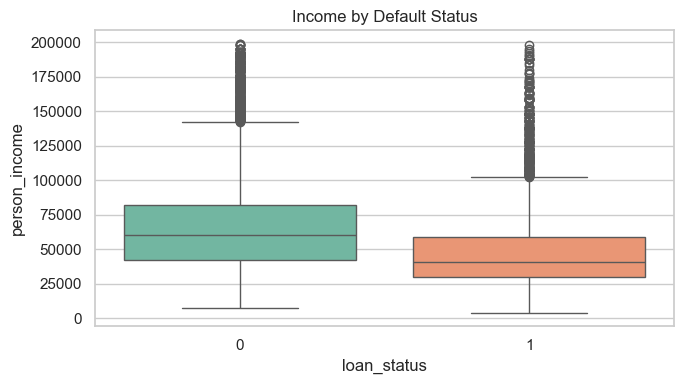

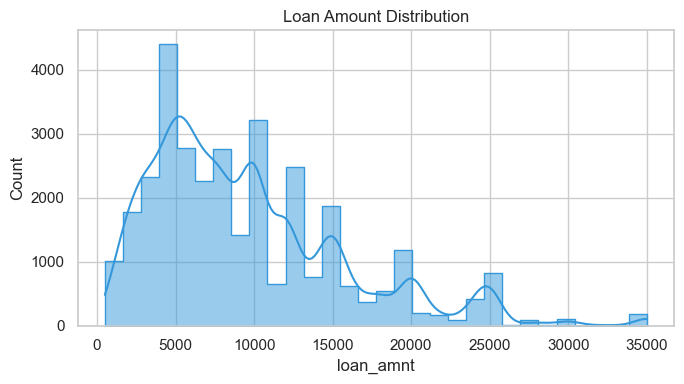

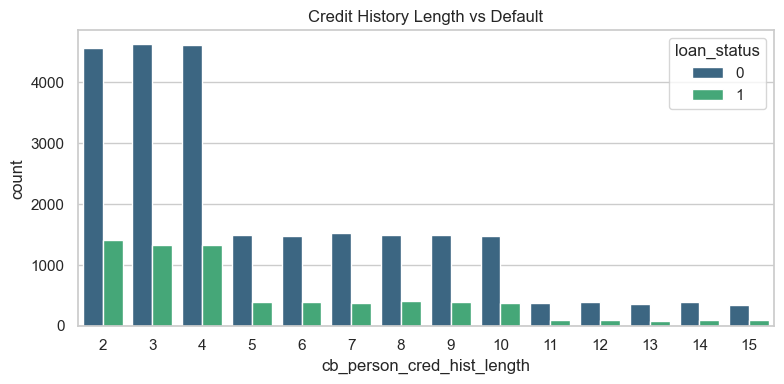

C:\Users\umana\AppData\Local\Temp\ipykernel_20240\1493849596.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


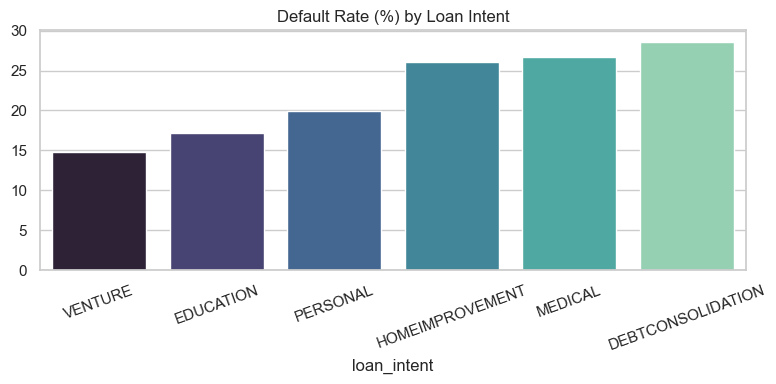

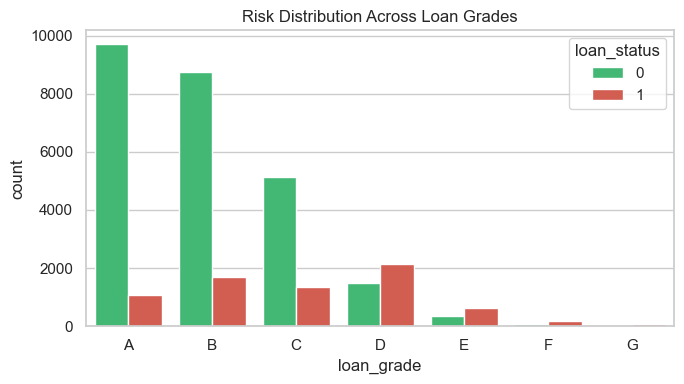

In [5]:
os.makedirs("../assets", exist_ok=True)
sns.set_theme(style="whitegrid")

# 1. Income Distribution vs Default
plt.figure(figsize=(7, 4))
sns.boxplot(
    x="loan_status",
    y="person_income",
    data=df[df["person_income"] < 200000],
    palette="Set2",
)
plt.title("Income by Default Status")
plt.tight_layout()
plt.savefig("../assets/eda_income_patterns.png", dpi=300)
plt.show()

# 2. Loan Amounts Distribution
plt.figure(figsize=(7, 4))
sns.histplot(
    df["loan_amnt"], bins=30, kde=True, color="#3498db", element="step"
)
plt.title("Loan Amount Distribution")
plt.tight_layout()
plt.savefig("../assets/eda_loan_amounts.png", dpi=300)
plt.show()

# 3. Credit History vs Default
plt.figure(figsize=(8, 4))
sns.countplot(
    x="cb_person_cred_hist_length",
    hue="loan_status",
    data=df[df["cb_person_cred_hist_length"] <= 15],
    palette="viridis",
)
plt.title("Credit History Length vs Default")
plt.tight_layout()
plt.savefig("../assets/eda_cred_history.png", dpi=300)
plt.show()

# 4. Default by Intent
plt.figure(figsize=(8, 4))
default_by_intent = (
    df.groupby("loan_intent")["loan_status"].mean().sort_values() * 100
)
sns.barplot(
    x=default_by_intent.index, y=default_by_intent.values, palette="mako"
)
plt.title("Default Rate (%) by Loan Intent")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../assets/eda_default_trends_intent.png", dpi=300)
plt.show()

# 5. Risk Distribution Across Grades
plt.figure(figsize=(7, 4))
sns.countplot(
    x="loan_grade",
    hue="loan_status",
    data=df,
    order=["A", "B", "C", "D", "E", "F", "G"],
    palette=["#2ecc71", "#e74c3c"],
)
plt.title("Risk Distribution Across Loan Grades")
plt.tight_layout()
plt.savefig("../assets/eda_risk_distribution_grade.png", dpi=300)
plt.show()